In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import os
import random
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Dropout,Conv2D,MaxPooling2D,Flatten
from keras.models import load_model
import cv2
from tensorflow.keras import layers

In [69]:
train_path=r'c:\Users\HP\Downloads\Intell Secen Classification\seg_train\seg_train'
test_path=r'c:\Users\HP\Downloads\Intell Secen Classification\seg_test\seg_test'


# Classes

In [70]:
classes_train=os.listdir(train_path)
print("Classes in train folder: ",classes_train)
for label,class_name in enumerate(classes_train):
     print(f"Class {label}: {class_name}")

Classes in train folder:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class 0: buildings
Class 1: forest
Class 2: glacier
Class 3: mountain
Class 4: sea
Class 5: street


In [71]:
classes_train

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [72]:
classes_test=os.listdir(test_path)
print("Classes in train folder: ",classes_test)
for label,class_name in enumerate(classes_test):
     print(f"Class {label}: {class_name}")

Classes in train folder:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class 0: buildings
Class 1: forest
Class 2: glacier
Class 3: mountain
Class 4: sea
Class 5: street


In [73]:
classes_test

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

# Count  images

In [74]:
print("Number of images in train folder")
for i in classes_train:
    folder=os.path.join(train_path,i)
    len_images=len([file for file in os.listdir(folder)
                    if file.lower().endswith(('.jpg','.png','.jpeg'))])
    print("Number of images in ",i," ",len_images)

Number of images in train folder
Number of images in  buildings   2191
Number of images in  forest   2271
Number of images in  glacier   2404
Number of images in  mountain   2512
Number of images in  sea   2274
Number of images in  street   2382


In [75]:
print("Number of images in train folder")
for i in classes_test:
    folder=os.path.join(test_path,i)
    len_images=len([file for file in os.listdir(folder)
                    if file.lower().endswith(('.jpg','.png','.jpeg'))])
    print("Number of images in ",i," ",len_images)

Number of images in train folder
Number of images in  buildings   437
Number of images in  forest   474
Number of images in  glacier   553
Number of images in  mountain   525
Number of images in  sea   510
Number of images in  street   501


# Sample images

In [35]:
import random

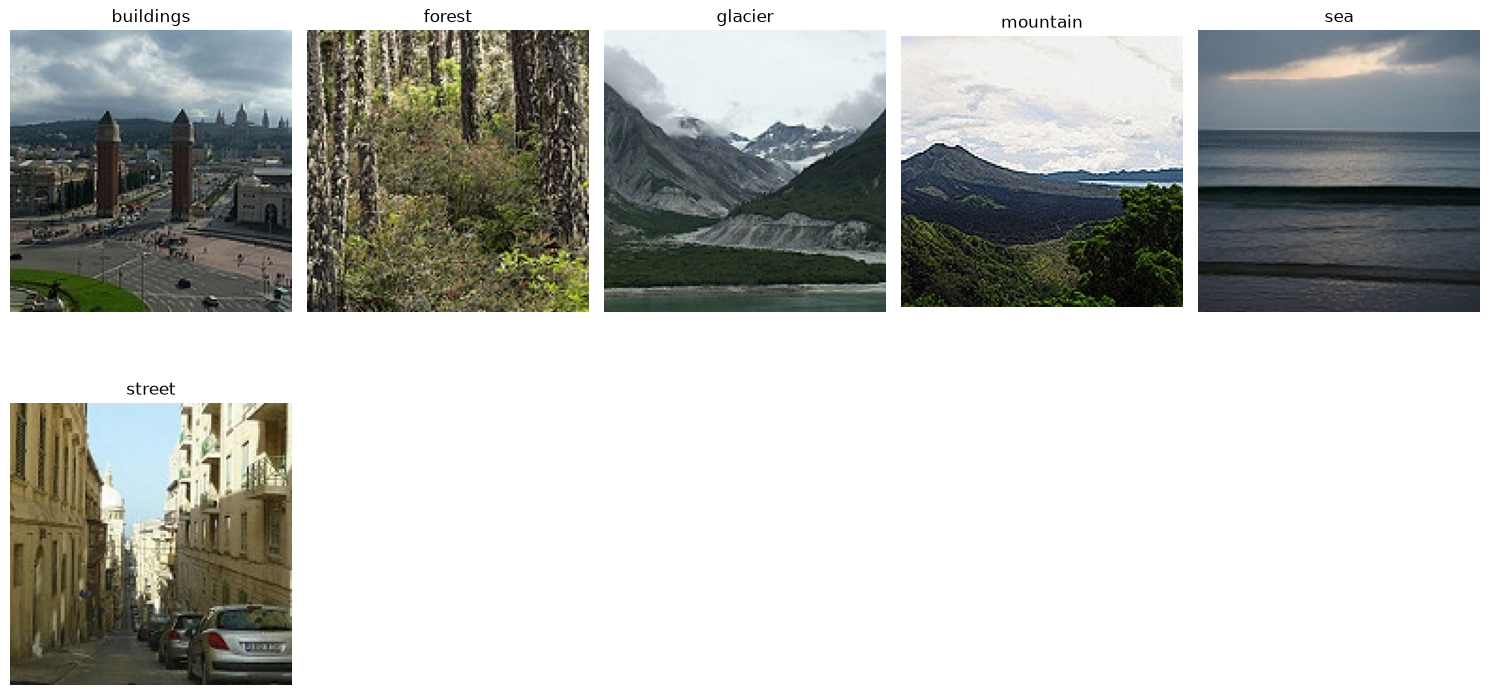

In [76]:
plt.figure(figsize=(15, 8))
for i,label in enumerate(classes_train):
    folder=os.path.join(train_path,label)
    images=[file for file in os.listdir(folder)
        if file.lower().endswith(('.jpg','.png','.jpeg'))]
    if len(images)>0:
        images_path=os.path.join(folder,random.choice(images))
        image=plt.imread(images_path)
        plt.subplot(2,5,i+1)
        plt.imshow(image)
        plt.title(label)
        plt.axis('off')
plt.tight_layout()
plt.show()

# Data Generator

In [37]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [77]:
train_dataden=ImageDataGenerator(
    rescale=1.0/255.0,#Convert pixel into 0-1
    rotation_range=20,# rotate image
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True
    
)

In [78]:
test_datagen=ImageDataGenerator(
    rescale=1/255
)

# Train data

In [79]:
train_data = train_dataden.flow_from_directory(
    train_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

Found 14034 images belonging to 6 classes.


# Test Data

In [85]:
test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(128,128),
    batch_size=25,
    class_mode='categorical',
    shuffle=False
)

Found 3000 images belonging to 6 classes.


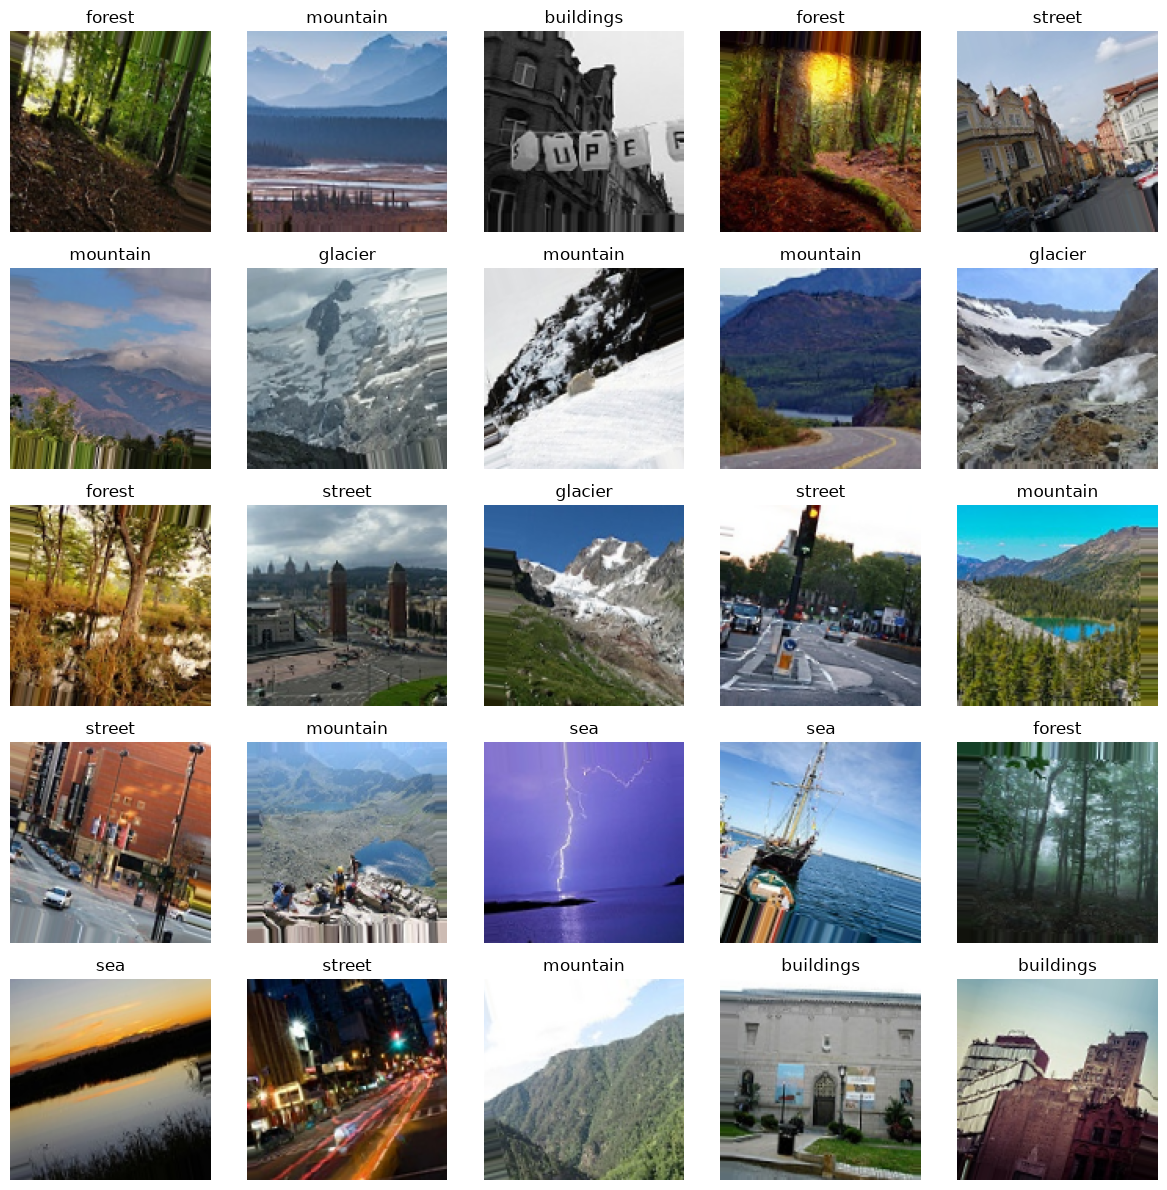

In [82]:
image,label=next(train_data)
plt.figure(figsize=(12, 12))
for i in range(min(25,len(image))):
    plt.subplot(5,5,i+1)
    plt.imshow(image[i])
    plt.title(classes_train[np.argmax(label[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

# Model

In [45]:
model=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(128,128,3)),
    MaxPooling2D((2,2)),
    
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    
    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    
    Conv2D(256,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.5),
    
    Dense(6, activation='softmax')
    
])

c:\Users\HP\OneDrive\Desktop\DEEP LEARNING\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Complie

In [46]:
from tensorflow.keras.optimizers import Adam

adam = Adam(learning_rate=0.001)

In [48]:
model.compile(
    optimizer=adam,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Summary

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,568,966 (5.99 MB)

 Trainable params: 1,568,966 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=100,
)

Epoch 1/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 231s 517ms/step - accuracy: 0.5310 - loss: 1.1618 - val_accuracy: 0.6327 - val_loss: 0.9504
Epoch 2/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 199s 453ms/step - accuracy: 0.6518 - loss: 0.9188 - val_accuracy: 0.7240 - val_loss: 0.7479
Epoch 3/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 253s 576ms/step - accuracy: 0.7061 - loss: 0.8106 - val_accuracy: 0.7507 - val_loss: 0.6734
Epoch 4/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 223s 507ms/step - accuracy: 0.7502 - loss: 0.7043 - val_accuracy: 0.8037 - val_loss: 0.5569
Epoch 5/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 233s 530ms/step - accuracy: 0.7711 - loss: 0.6475 - val_accuracy: 0.8243 - val_loss: 0.5057
Epoch 6/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 220s 500ms/step - accuracy: 0.7875 - loss: 0.6106 - val_accuracy: 0.8177 - val_loss: 0.5193
Epoch 7/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 226s 514ms/step - accuracy: 0.7939 - loss: 0.5838 - val_accuracy: 0.8423 - val_loss: 0.4486
Epoch 8/100
439/439 ━━━━━━━━━━━━━━━━━━━━ 299s 681ms/step - accuracy: 

# Evualate

In [52]:
loss,accuracy=model.evaluate(test_data)

94/94 ━━━━━━━━━━━━━━━━━━━━ 15s 153ms/step - accuracy: 0.8697 - loss: 0.5134


In [53]:
print("Loss: ",loss)
print("Accuracy",accuracy)

Loss:  0.513375461101532
Accuracy 0.8696666955947876


# Graph

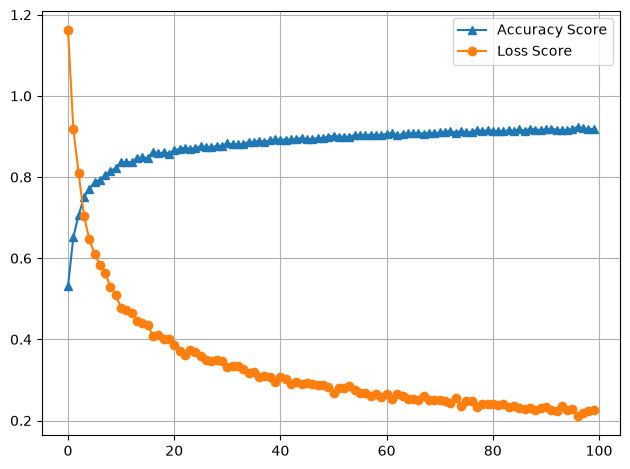

In [54]:
plt.plot(history.history['accuracy'],label='Accuracy Score',marker='^')
plt.plot(history.history['loss'],label='Loss Score',marker='o')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Prediction

In [65]:
from sklearn.metrics import accuracy_score

In [66]:
prediction=model.predict(test_data,verbose=1)
y_pred=np.argmax(prediction,axis=1)
y_true=test_data.classes
accuracy=accuracy_score(y_true,y_pred)
print("Accuracy Acore",accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step
Accuracy Acore 0.8696666666666667


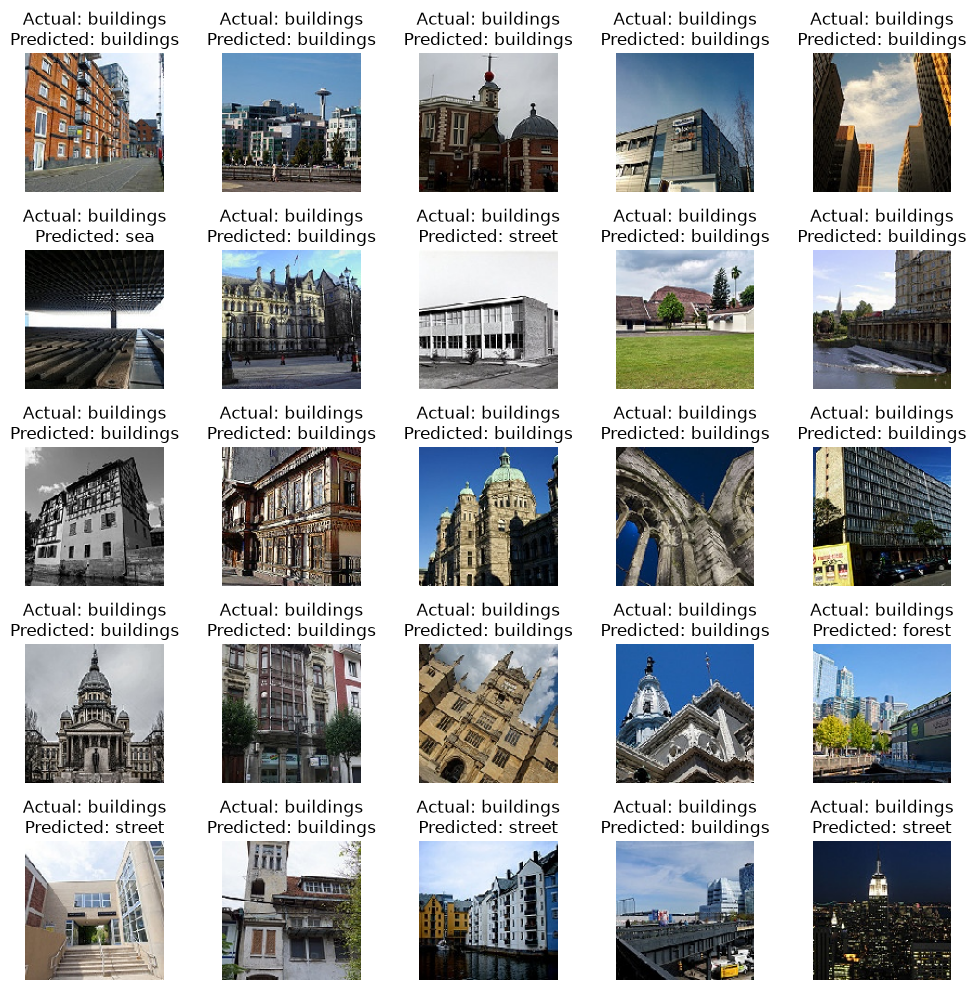

In [87]:
image, label = next(test_data)
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.imshow(image[i])
    actual = np.argmax(label[i])
    predicted = y_pred[i]
    plt.title(f"Actual: {classes_test[actual]}\nPredicted: {classes_test[predicted]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Wrong indices

In [90]:
wrong_prediction=np.where(y_true!=y_pred)
len(wrong_prediction)

1

In [92]:
model=load_model('Intel_Scene_Classification.keras')

In [180]:
images_path=r'c:\Users\HP\Downloads\Intell Secen Classification\seg_pred\seg_pred\8650.jpg'

In [181]:
import cv2

In [182]:
image=cv2.imread(images_path)

In [183]:
image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

In [184]:
image=cv2.resize(image,(128,128))


In [185]:
image = image.astype("float32") / 255.0

In [186]:
test_image=np.expand_dims(image, axis=0)
print(test_image.shape)

(1, 128, 128, 3)


In [187]:
prediction = model.predict(test_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


In [188]:
predict_index=np.argmax(prediction[0])
predict_class=classes_test[predict_index]
confidence=prediction[0][predict_index]

In [189]:
print("Prediction:", predict_class)
print("Confidence:", confidence, "%")

Prediction: forest
Confidence: 1.0 %


Text(0.5, 1.0, 'Predict: forest,\nConfidence1.0')

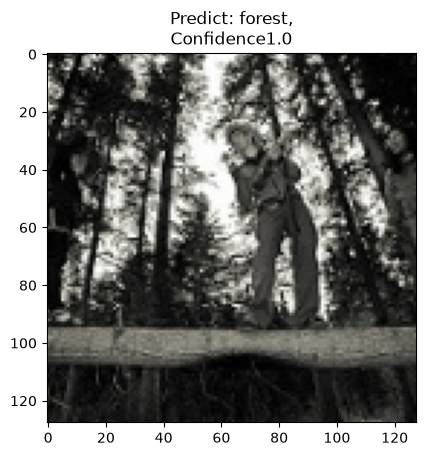

In [190]:
plt.imshow(test_image[0])
plt.title(f"Predict: {predict_class},\nConfidence{confidence}")
